Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

iris = load_iris()
X_raw, y = iris.data, iris.target
names = iris.target_names
X = StandardScaler().fit_transform(X_raw)
print(pd.DataFrame(X_raw, columns=iris.feature_names).describe().round(2))

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.00               4.35   
75%                 6.40              3.30               5.10   
max                 7.90              4.40               6.90   

       petal width (cm)  
count            150.00  
mean               1.20  
std                0.76  
min                0.10  
25%                0.30  
50%                1.30  
75%                1.80  
max                2.50  


Agglomerative, comparing linkage method

single    cophenetic=0.830 silhouette=0.505 ARI=0.558
complete  cophenetic=0.751 silhouette=0.450 ARI=0.573
average   cophenetic=0.854 silhouette=0.480 ARI=0.562
ward      cophenetic=0.823 silhouette=0.447 ARI=0.615


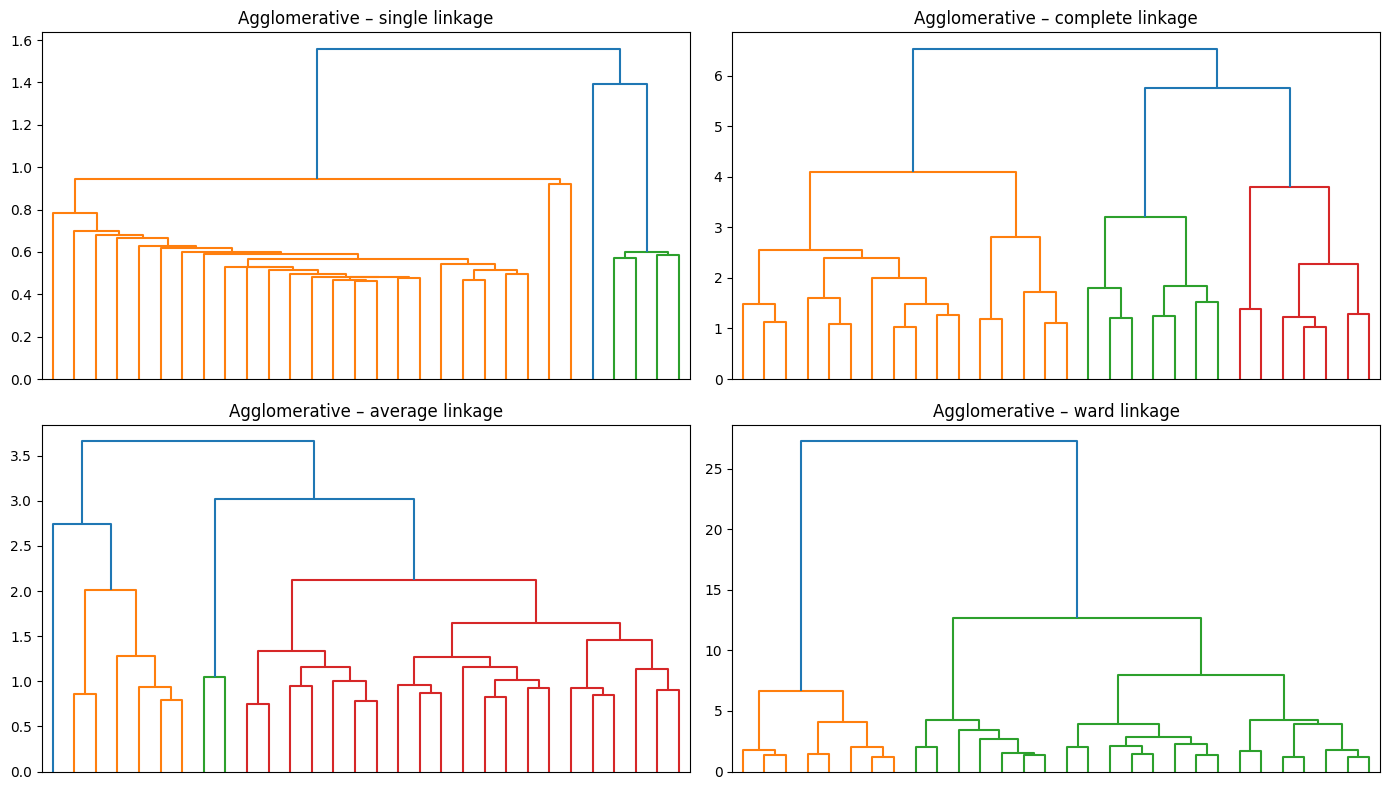

In [2]:
D = pdist(X)
results = {}
for method in ["single", "complete", "average", "ward"]:
    Z = linkage(X, method=method)
    labels = fcluster(Z, 3, "maxclust")
    results[method] = Z
    print(f"{method:9s} cophenetic={cophenet(Z, D)[0]:.3f} "
          f"silhouette={silhouette_score(X, labels):.3f} "
          f"ARI={adjusted_rand_score(y, labels):.3f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (m, Z) in zip(axes.ravel(), results.items()):
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, no_labels=True)
    ax.set_title(f"Agglomerative – {m} linkage")
plt.tight_layout(); plt.show()

Divisive (top-down bisecting) with a real dendrogram

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


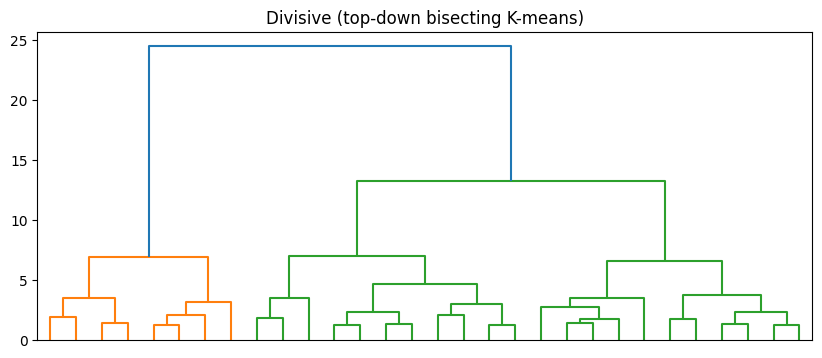

In [3]:
def sse(A): return ((A - A.mean(0))**2).sum()

def divisive_linkage(X, seed=0):
    n, nodes = len(X), []
    def split(idx):
        if len(idx) == 1: return ("leaf", idx[0])
        km = KMeans(2, n_init=10, random_state=seed).fit(X[idx])
        a, b = idx[km.labels_ == 0], idx[km.labels_ == 1]
        if len(a) == 0 or len(b) == 0:          # identical points
            a, b = idx[:1], idx[1:]
        l, r = split(a), split(b)
        nodes.append(dict(h=np.sqrt(sse(X[idx])), size=len(idx), l=l, r=r))
        return ("node", len(nodes) - 1)
    split(np.arange(n))
    order = sorted(range(len(nodes)), key=lambda k: (nodes[k]["h"], nodes[k]["size"]))
    new_id = {k: n + r for r, k in enumerate(order)}
    cid = lambda ref: ref[1] if ref[0] == "leaf" else new_id[ref[1]]
    Z = np.zeros((n - 1, 4))
    for r, k in enumerate(order):
        nd = nodes[k]
        Z[r] = [cid(nd["l"]), cid(nd["r"]), nd["h"], nd["size"]]
    return Z

Z_div = divisive_linkage(X)
plt.figure(figsize=(10, 4))
dendrogram(Z_div, truncate_mode="lastp", p=30, no_labels=True)
plt.title("Divisive (top-down bisecting K-means)"); plt.show()

Head-to-head evaluation (Unit 3’s internal and external measures)

In [4]:
Z_agg = results["ward"]
rows = []
for name, Z in [("Agglomerative (Ward)", Z_agg), ("Divisive (bisecting)", Z_div)]:
    lab = fcluster(Z, 3, "maxclust")
    rows.append({"Method": name,
                 "Cophenetic corr": cophenet(Z, D)[0],
                 "Silhouette (internal)": silhouette_score(X, lab),
                 "Rand (external)": rand_score(y, lab),
                 "Adj. Rand (external)": adjusted_rand_score(y, lab)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

              Method  Cophenetic corr  Silhouette (internal)  Rand (external)  Adj. Rand (external)
Agglomerative (Ward)            0.823                  0.447            0.825                 0.615
Divisive (bisecting)            0.830                  0.459            0.828                 0.610


Interpret the sub-species groups

True species  setosa  versicolor  virginica
Cluster                                    
1                 49           0          0
2                  1          27          2
3                  0          23         48
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
1               5.02              3.45               1.47              0.24
2               5.53              2.57               3.93              1.21
3               6.55              2.99               5.27              1.85


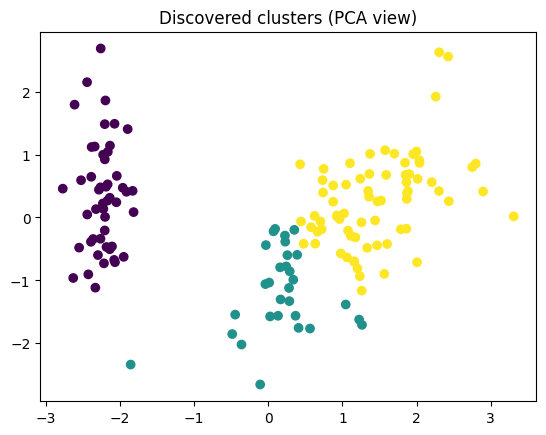

In [5]:
labels = fcluster(Z_agg, 3, "maxclust")
print(pd.crosstab(pd.Series(labels, name="Cluster"),
                  pd.Series(names[y], name="True species")))

profile = pd.DataFrame(X_raw, columns=iris.feature_names).groupby(labels).mean().round(2)
print(profile)   # which measurements define each cluster

P = PCA(2).fit_transform(X)
plt.scatter(P[:, 0], P[:, 1], c=labels, cmap="viridis")
plt.title("Discovered clusters (PCA view)"); plt.show()